In [1]:
from google.colab import auth
auth.authenticate_user()

In [3]:
import pandas as pd
import pandas_gbq
import matplotlib.pyplot as plt

In [4]:
project_id = "connecticut-prison-analysis"

query = """
SELECT *
FROM `connecticut-prison-analysis.connecticut.sentenced_stays`
"""

stays = pandas_gbq.read_gbq(query, project_id=project_id)

Downloading: 100%|██████████|


In [6]:
len(stays)
stays.info()
stays.head()
columns_to_fix = stays.select_dtypes("dbdate").columns
for col in columns_to_fix:
  stays[col] = pd.to_datetime(stays[col])
stays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75250 entries, 0 to 75249
Data columns (total 39 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   identifier                             75250 non-null  object
 1   stay_id                                75250 non-null  object
 2   latest_admission_date                  75250 non-null  dbdate
 3   race                                   75250 non-null  object
 4   gender                                 75250 non-null  object
 5   age                                    75250 non-null  Int64 
 6   age_bucket                             75250 non-null  object
 7   facility                               75250 non-null  object
 8   fac_category                           75250 non-null  object
 9   offense                                75250 non-null  object
 10  off_category                           75250 non-null  object
 11  class          

In [10]:
stays = stays.sort_values(["identifier", "first_seen_per_stay"])
stays.head()

stays["next_stay_start"] = stays.groupby("identifier")["first_seen_per_stay"].shift(-1)
stays["days_before_next_stay"] = (stays["next_stay_start"] - stays["last_seen_per_stay"]).dt.days.astype("Int64")
stays["days_before_next_stay"].describe()

released_per_stay = stays[stays["released_per_stay_flag"] == 1].copy()
max_date = stays["last_seen_per_stay"].max()
released_per_stay["follow_up_days"] = (max_date - released_per_stay["last_seen_per_stay"]).dt.days

released_per_stay["eligibility_30"] = released_per_stay["follow_up_days"] >= 30
released_per_stay["eligibility_90"] = released_per_stay["follow_up_days"] >= 90
released_per_stay["eligibility_365"] = released_per_stay["follow_up_days"] >= 365
released_per_stay["eligibility_1095"] = released_per_stay["follow_up_days"] >= 1095

released_per_stay["readmission_30"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 30))
released_per_stay["readmission_90"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 90))
released_per_stay["readmission_365"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 365))
released_per_stay["readmission_1095"] = (released_per_stay["days_before_next_stay"].notna() & (released_per_stay["days_before_next_stay"] <= 1095))

eligible_30 = released_per_stay[released_per_stay["eligibility_30"]].copy()
count_30 = len(eligible_30)
readmit_30 = (eligible_30["readmission_30"].mean() * 100).round(2)

eligible_90 = released_per_stay[released_per_stay["eligibility_90"]].copy()
count_90 = len(eligible_90)
readmit_90 = (eligible_90["readmission_90"].mean() * 100).round(2)

eligible_365 = released_per_stay[released_per_stay["eligibility_365"]].copy()
count_365 = len(eligible_365)
readmit_365 = (eligible_365["readmission_365"].mean() * 100).round(2)

eligible_1095 = released_per_stay[released_per_stay["eligibility_1095"]].copy()
count_1095 = len(eligible_1095)
readmit_1095 = (eligible_1095["readmission_1095"].mean() * 100).round(2)

readmission_summary = pd.DataFrame({
                      "readmit_days": [30, 90, 365, 1095],
                      "percentage" : [readmit_30, readmit_90, readmit_365, readmit_1095],
                      "eligible_stays": [count_30, count_90, count_365, count_1095]})
readmission_summary

,readmit_days,percentage,eligible_stays
0,30,5.47,67281
1,90,9.83,66047
2,365,21.23,60569
3,1095,35.43,46312


In [14]:
def groupby_yr_rate(df, group_col):
  """One-year readmission rate and eligible stay count by group"""
  result = df.groupby(group_col, dropna = False).agg(yr_return_percentage = ("readmission_365", "mean"), yr_eligible_stays = ("stay_id", "count")).sort_values("yr_return_percentage", ascending = False)
  result["yr_return_percentage"] = (result["yr_return_percentage"] * 100).round(2)
  return result

display(groupby_yr_rate(eligible_365, "off_category"))
display(groupby_yr_rate(eligible_365, "age_bucket"))
display(groupby_yr_rate(eligible_365, "release_timing"))
display(groupby_yr_rate(eligible_365, "race"))
display(groupby_yr_rate(eligible_365, "sentence_day_buckets"))
display(groupby_yr_rate(eligible_365, "has_special_parole"))


,yr_return_percentage,yr_eligible_stays
off_category,,
Property,29.05,8285
Warrant/Hold/Procedural,26.17,298
Unknown,24.21,2342
Weapons,23.15,3888
Violent,22.57,10935
Public Order/Obstruction,22.01,2376
Court/Supervision Violation,21.55,16929
Drug,20.6,5824
Sexual,17.97,1887


,yr_return_percentage,yr_eligible_stays
age_bucket,,
Under 18,31.63,98
18-24,24.7,6049
55+,23.44,6757
35-44,21.05,17500
25-34,20.39,19899
45-54,19.54,10266


,yr_return_percentage,yr_eligible_stays
release_timing,,
Unknown,51.26,796
Released Early,29.34,31031
Released After End Date,15.3,183
Released at End of Sentence,11.6,28559


,yr_return_percentage,yr_eligible_stays
race,,
Amer Ind,26.02,196
Black,23.05,21267
Hispanic,20.75,15370
White,19.88,23423
Asian,17.89,313


,yr_return_percentage,yr_eligible_stays
sentence_day_buckets,,
20+ years,51.76,1476
3-5 years,27.34,7524
10-20 years,26.09,1840
1-3 years,24.55,16101
5-10 years,23.89,5274
6 months-1 year,17.24,14695
Under 6 months,13.24,13659


,yr_return_percentage,yr_eligible_stays
has_special_parole,,
0,21.25,55739
1,20.89,4830


In [15]:
def groupby_3yr_rate(df, group_col):
  """Three-year readmission rate and eligible stay count by group"""
  result = df.groupby(group_col, dropna = False).agg(three_yr_return_percentage = ("readmission_1095", "mean"),
                                                     three_yr_eligible_stays = ("stay_id", "count")).sort_values("three_yr_return_percentage", ascending = False)
  result["three_yr_return_percentage"] = (result["three_yr_return_percentage"] * 100).round(2)
  return result

display(groupby_3yr_rate(eligible_365, "off_category"))
display(groupby_3yr_rate(eligible_365, "age_bucket"))
display(groupby_3yr_rate(eligible_365, "release_timing"))
display(groupby_3yr_rate(eligible_365, "race"))
display(groupby_3yr_rate(eligible_365, "sentence_day_buckets"))
display(groupby_3yr_rate(eligible_365, "has_special_parole"))

,three_yr_return_percentage,three_yr_eligible_stays
off_category,,
Property,45.62,8285
Warrant/Hold/Procedural,44.3,298
Public Order/Obstruction,39.31,2376
Weapons,37.73,3888
Court/Supervision Violation,37.46,16929
Unknown,37.15,2342
Violent,35.76,10935
Drug,33.55,5824
Sexual,27.87,1887


,three_yr_return_percentage,three_yr_eligible_stays
age_bucket,,
Under 18,57.14,98
18-24,43.45,6049
25-34,35.86,19899
35-44,35.32,17500
45-54,31.76,10266
55+,31.48,6757


,three_yr_return_percentage,three_yr_eligible_stays
release_timing,,
Unknown,63.32,796
Released Early,39.01,31031
Released After End Date,37.16,183
Released at End of Sentence,30.5,28559


,three_yr_return_percentage,three_yr_eligible_stays
race,,
Amer Ind,39.8,196
Black,38.67,21267
Hispanic,35.13,15370
White,32.43,23423
Asian,28.75,313


,three_yr_return_percentage,three_yr_eligible_stays
sentence_day_buckets,,
20+ years,56.23,1476
3-5 years,39.9,7524
1-3 years,38.48,16101
5-10 years,37.47,5274
10-20 years,34.84,1840
6 months-1 year,34.17,14695
Under 6 months,27.26,13659


,three_yr_return_percentage,three_yr_eligible_stays
has_special_parole,,
1,39.67,4830
0,34.93,55739


,stays,percent
gap_bucket,,
Within 30 days,3703,13.0
31-90 days,2928,10.3
91-180 days,3174,11.2
181-365 days,4192,14.8
Over 1 year,8532,30.0
Over 3 years,5869,20.7


<Axes: title={'center': 'Time Between Sentenced Release and Next Sentenced Admission'}, xlabel='Number of Stays', ylabel='Days until next admission'>

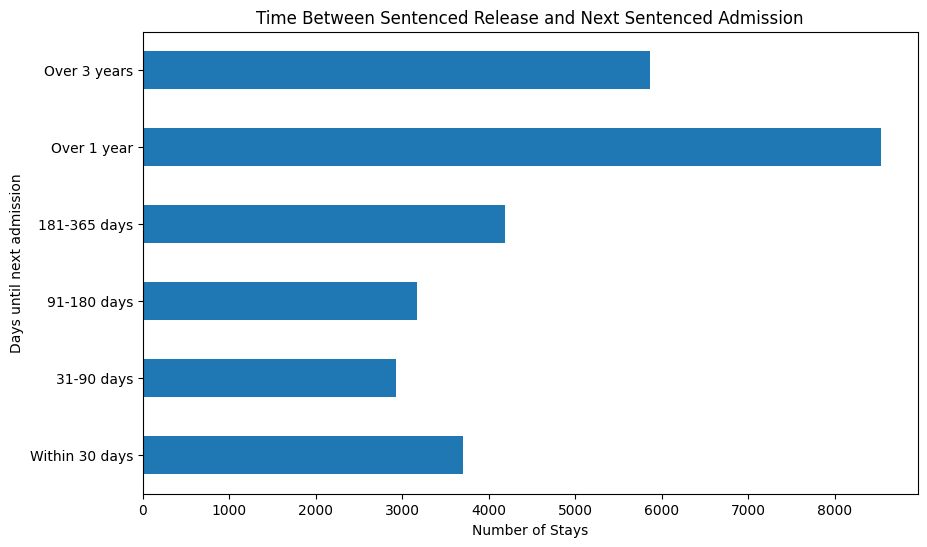

In [16]:
returned = released_per_stay[released_per_stay["days_before_next_stay"].notna()].copy()

gap_bins = [0, 30, 90, 180, 365, 1095, float("inf")]
gap_labels = ["Within 30 days", "31-90 days", "91-180 days", "181-365 days", "Over 1 year", "Over 3 years"]

returned["gap_bucket"] = pd.cut(
    returned["days_before_next_stay"].astype(float),
    bins=gap_bins,
    labels=gap_labels
)

gap_counts = returned["gap_bucket"].value_counts(sort=False)
gap_pct = (gap_counts / gap_counts.sum() * 100).round(1)

display(pd.DataFrame({"stays": gap_counts, "percent": gap_pct}))

# Plot
gap_counts.plot(kind="barh", figsize=(10, 6), title = "Time Between Sentenced Release and Next Sentenced Admission", xlabel = "Number of Stays", ylabel = "Days until next admission")